<H1> Financial Market Dynamics: Statistical Modelling, Econometric Analysis and Time-Series Forecasting of the S&P 500 (2016–2026) </H1>

<B1> **Research question:** To what extent can financial market indicators explain fluctuations in S&P 500 returns, and how effectively can historical market data be used to forecast future market movements? </B1>

<B1> **Phase 2: Time-series analysis and forecasting**  </B1>

<B1> **Name:** Syed Zaid </B1> 

<B1> **Dataset Source:** Federal Reserve Bank of St. Louis – Federal Reserve Economic Data (FRED) </B1> 

<B1> **Domain:** Financial Markets, Stock Market Volatility and Macroeconomic Indicators </B1> 

<B1> **Study Period:** October 2016 – October 2026. </B1>

# Phase 2: Time-series analysis and forecasting

<H2> 1. Time-Series Data Preparation </H2>

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Time-series analysis
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Statistical modelling
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

# Evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Load cleaned financial dataset
from pathlib import Path

# Locate the project root
current_dir = Path.cwd().resolve()

if (current_dir / "Data").exists():
    PROJECT_ROOT = current_dir
elif (current_dir.parent / "Data").exists():
    PROJECT_ROOT = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not locate the project root. "
        "Run the notebook from the project root or Notebooks folder."
    )

# Load cleaned financial dataset
DATA_PATH = PROJECT_ROOT / "Data" / "Processed" / "Financial_dataset_cleaned.csv"

df = pd.read_csv(DATA_PATH)

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Set Date as index
df.set_index('Date', inplace=True)

# Sort chronologically
df.sort_index(inplace=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (2320, 10)


In [3]:
print("Dataset shape:", df.shape)

print("\nDate range:")
print("Start:", df.index.min())
print("End:", df.index.max())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst five observations:")
display(df.head())

Dataset shape: (2320, 10)

Date range:
Start: 2016-11-04 00:00:00
End: 2026-10-27 00:00:00

Data types:
SP500_Close            float64
VIX                    float64
Treasury_10Y           float64
Brent_Oil              float64
Fed_Rate               float64
SP500_Return           float64
VIX_Change             float64
Treasury_10Y_Change    float64
Brent_Oil_Return       float64
Fed_Rate_Change        float64
dtype: object

Missing values:
SP500_Close            0
VIX                    0
Treasury_10Y           0
Brent_Oil              0
Fed_Rate               0
SP500_Return           0
VIX_Change             0
Treasury_10Y_Change    0
Brent_Oil_Return       0
Fed_Rate_Change        0
dtype: int64

First five observations:


,SP500_Close,VIX,Treasury_10Y,Brent_Oil,Fed_Rate,SP500_Return,VIX_Change,Treasury_10Y_Change,Brent_Oil_Return,Fed_Rate_Change
Date,,,,,,,,,,
2016-11-04,2085.1800,22.5100,1.7900,43.0600,0.4100,-0.1666,0.4300,-0.0300,-1.7792,0.0000
2016-11-07,2131.5200,18.7100,1.8300,42.8300,0.4100,2.2224,-3.8000,0.0400,-0.5341,0.0000
2016-11-08,2139.5600,18.7400,1.8800,43.4700,0.4100,0.3772,0.0300,0.0500,1.4943,0.0000
2016-11-09,2163.2600,14.3800,2.0700,43.8800,0.4100,1.1077,-4.3600,0.1900,0.9432,0.0000
2016-11-10,2167.4800,14.7400,2.1500,43.6700,0.4100,0.1951,0.3600,0.0800,-0.4786,0.0000


In [4]:
# Extract S&P 500 daily returns
sp500_returns = df['SP500_Return'].copy()

# Verify the extracted series
print("Number of observations:", len(sp500_returns))
print("Mean return:", sp500_returns.mean())
print("Standard deviation:", sp500_returns.std())

display(sp500_returns.head())

Number of observations: 2320
Mean return: 0.06598450894654684
Standard deviation: 1.1510783408501644


Date
2016-11-04   -0.1666
2016-11-07    2.2224
2016-11-08    0.3772
2016-11-09    1.1077
2016-11-10    0.1951
Name: SP500_Return, dtype: float64

## 3.2 Time-Series Visualisation and Decomposition

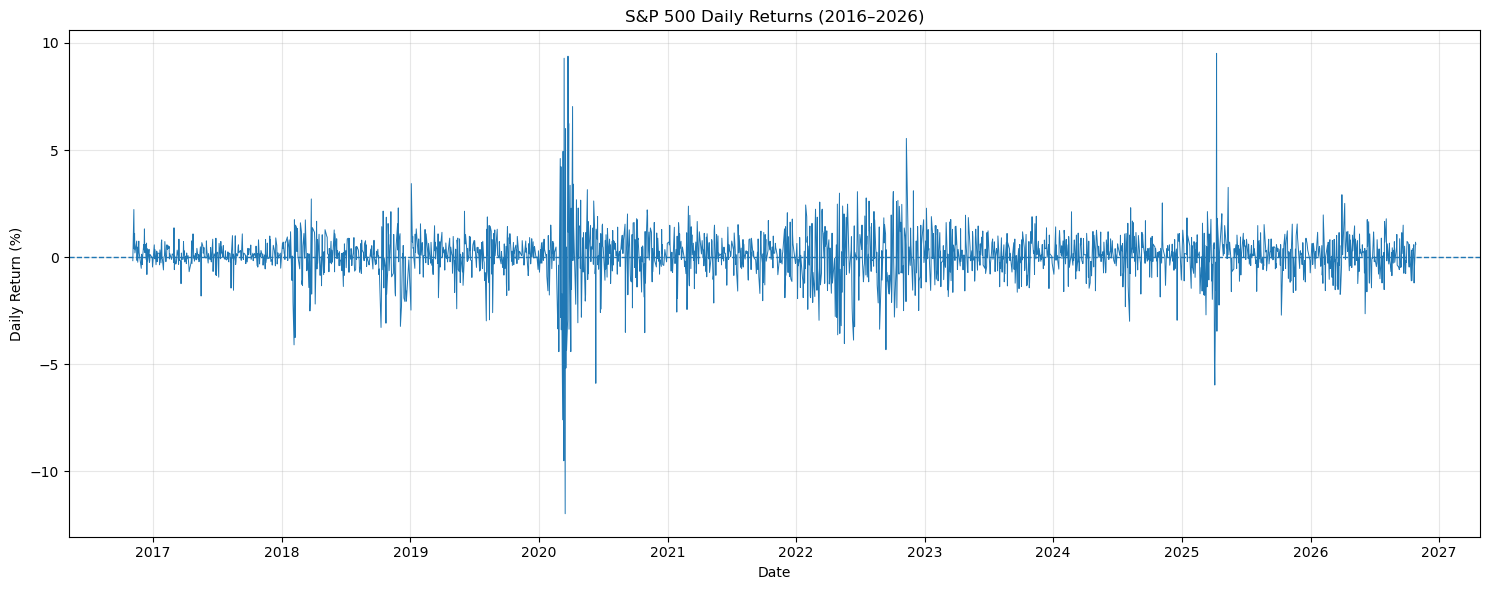

In [5]:
plt.figure(figsize=(15, 6))

plt.plot(
    sp500_returns.index,
    sp500_returns,
    linewidth=0.7
)

plt.axhline(
    y=0,
    linestyle='--',
    linewidth=1
)

plt.title('S&P 500 Daily Returns (2016–2026)')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

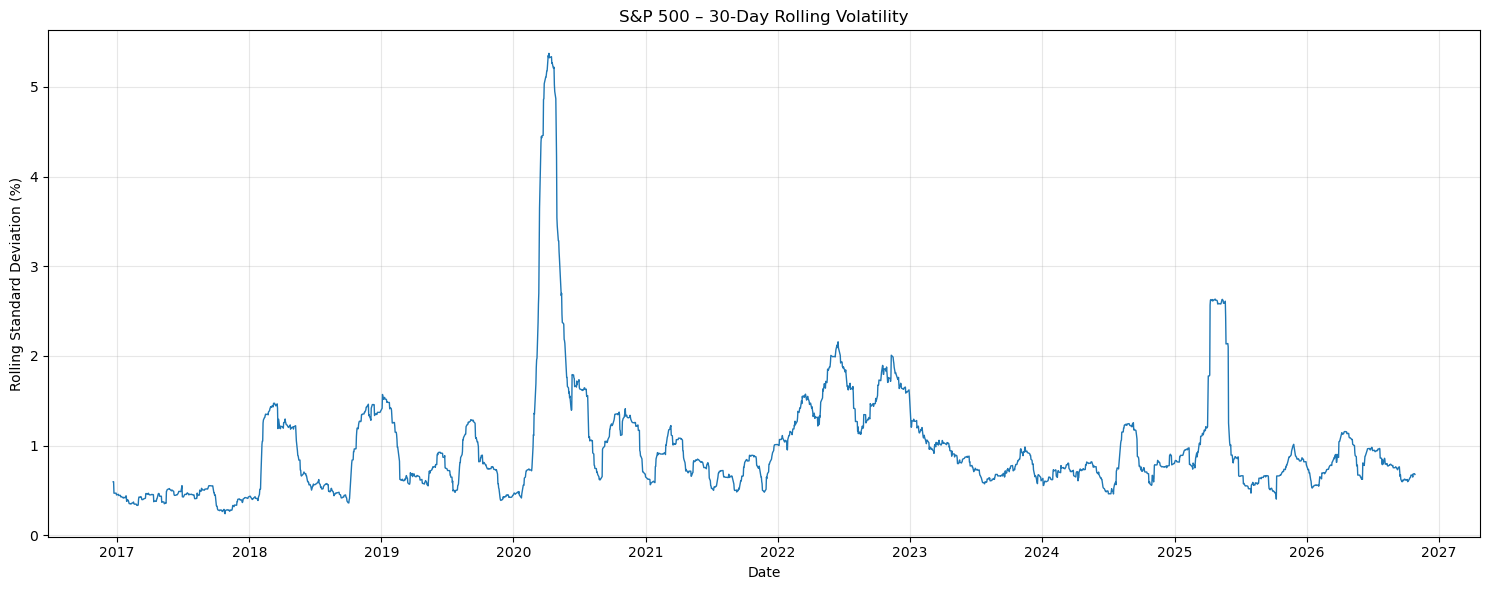

In [6]:
rolling_volatility = sp500_returns.rolling(
    window=30
).std()

plt.figure(figsize=(15, 6))

plt.plot(
    rolling_volatility.index,
    rolling_volatility,
    linewidth=1
)

plt.title('S&P 500 – 30-Day Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation (%)')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

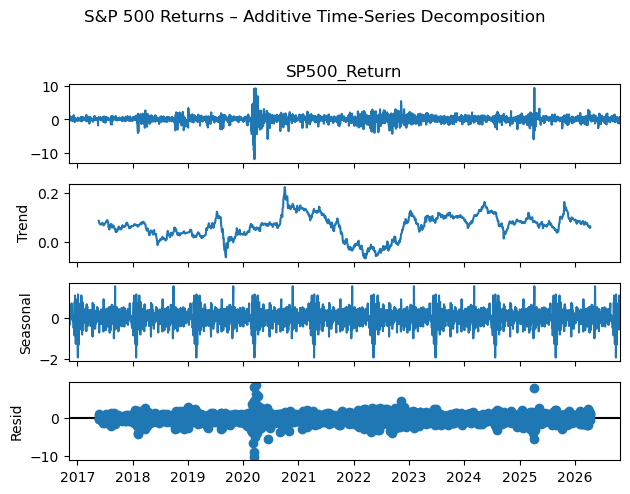

In [7]:
decomposition = seasonal_decompose(
    sp500_returns,
    model='additive',
    period=252
)

decomposition.plot()

plt.suptitle(
    'S&P 500 Returns – Additive Time-Series Decomposition',
    y=1.02
)

plt.tight_layout()
plt.show()

### Interpretation

The time-series visualisations provide an overview of the behaviour and volatility characteristics of S&P 500 daily returns between November 2016 and October 2026.

The historical return plot indicates that daily returns generally fluctuate around zero, with most observations exhibiting relatively small movements. However, several periods contain unusually large positive and negative returns, particularly around 2020 and 2025. This suggests that the variability of financial returns is not constant throughout the observation period.

The 30-trading-day rolling standard deviation further highlights these variations in market volatility. A substantial increase in volatility is observed around 2020, followed by elevated volatility during parts of 2022 and 2023, and another noticeable increase around 2025. These patterns provide visual evidence of volatility clustering, where periods of increased market volatility tend to occur in concentrated intervals.

The additive time-series decomposition separates the return series into observed, trend, seasonal and residual components. The trend component exhibits gradual variations over time, while the seasonal component does not reveal an obvious and consistent repeating pattern. The residual component retains considerable irregular variation, including extreme movements that are not captured by the trend or seasonal components.

Overall, the visualisations suggest that S&P 500 returns exhibit substantial short-term fluctuations, volatility clustering and irregular extreme movements. These characteristics indicate that the return series may contain complex time-dependent behaviour that requires further statistical investigation.

The decomposition uses an assumed period of 252 trading days, representing approximately one trading year. Therefore, the seasonal component should not be interpreted as definitive evidence of annual seasonality.

The next stage will examine the stationarity properties of the return series using formal statistical testing before proceeding with time-series model identification.

## 3.3 Stationarity Testing

In [8]:
# Augmented Dickey-Fuller test

adf_result = adfuller(
    sp500_returns,
    autolag='AIC'
)

print("Augmented Dickey-Fuller Test Results")
print("------------------------------------")
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Number of Lags:", adf_result[2])
print("Number of Observations:", adf_result[3])

print("\nCritical Values:")
for key, value in adf_result[4].items():
    print(f"{key}: {value}")

Augmented Dickey-Fuller Test Results
------------------------------------
ADF Statistic: -11.549933696247406
p-value: 3.4672320431734125e-21
Number of Lags: 23
Number of Observations: 2296

Critical Values:
1%: -3.4332013179632686
5%: -2.862799647940788
10%: -2.5674405676968886


C:\Users\reshma begum\AppData\Local\Temp\ipykernel_17428\2943394243.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


### Interpretation

The Augmented Dickey-Fuller (ADF) test was conducted to determine whether the S&P 500 daily return series exhibits stationarity.

The test produced an ADF statistic of -11.5499 and a p-value of approximately 3.47 × 10⁻²¹. Since the p-value is substantially below the 5% significance level, the null hypothesis of a unit root is rejected.

Furthermore, the ADF statistic is more negative than the critical values at the 1%, 5% and 10% significance levels. This provides additional statistical evidence supporting the stationarity of the return series.

The results indicate that S&P 500 daily returns are stationary over the examined sample period. Consequently, the series does not require differencing to achieve stationarity for the initial ARIMA specification.

Based on these findings, the initial ARIMA models will use an integration order of d = 0. Further examination of autocorrelation and partial autocorrelation will be conducted to guide the selection of autoregressive and moving-average components.

It is important to note that stationarity in the mean does not necessarily imply constant variance. The volatility clustering observed in the previous section suggests that additional modelling considerations may be necessary.

## 3.4 Autocorrelation and Partial Autocorrelation Analysis

<Figure size 1200x500 with 0 Axes>

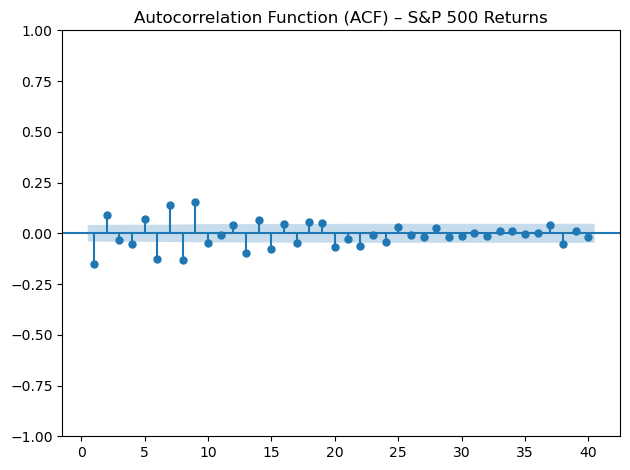

In [9]:
plt.figure(figsize=(12, 5))

plot_acf(
    sp500_returns,
    lags=40,
    zero=False
)

plt.title('Autocorrelation Function (ACF) – S&P 500 Returns')
plt.tight_layout()
plt.show()

<Figure size 1200x500 with 0 Axes>

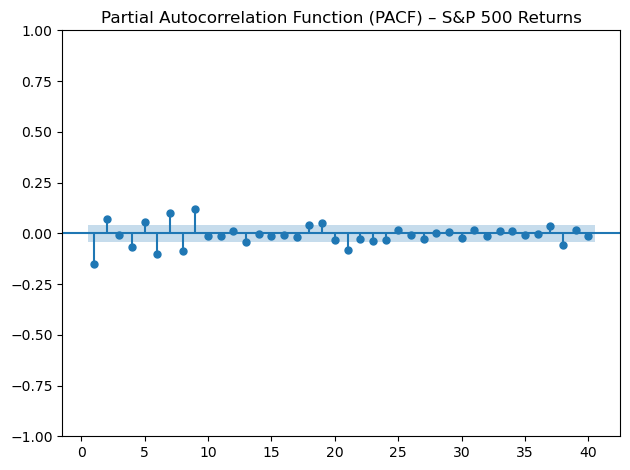

In [10]:
plt.figure(figsize=(12, 5))

plot_pacf(
    sp500_returns,
    lags=40,
    method='ywm',
    zero=False
)

plt.title('Partial Autocorrelation Function (PACF) – S&P 500 Returns')
plt.tight_layout()
plt.show()

### Interpretation

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots were examined to investigate the linear dependence between S&P 500 daily returns and their historical values.

The ACF plot indicates that several of the initial lags exhibit statistically significant autocorrelation, although the corresponding correlation coefficients are relatively small. Most subsequent lags remain close to zero, suggesting that the linear dependence between daily returns generally weakens across longer lag intervals.

The PACF plot also identifies some statistically significant relationships at shorter lags. However, the observed pattern does not provide a sufficiently clear cutoff to establish a definitive autoregressive order.

Overall, the ACF and PACF results suggest the presence of limited short-term autocorrelation in S&P 500 daily returns, while most of the linear dependence remains relatively weak. These findings indicate that autoregressive and moving-average components may capture some of the short-term structure in the return series.

Since the ADF test previously established stationarity, the initial ARIMA specifications will use an integration order of d = 0. The autoregressive and moving-average orders will be investigated through candidate model estimation and information criteria rather than being selected exclusively from visual inspection of the ACF and PACF plots.

The results also suggest that forecasting daily returns may be challenging because of their relatively weak linear dependence on historical returns.

## 3.5 ARIMA Model Identification

In [11]:
# Define chronological train-test split

split_index = int(len(sp500_returns) * 0.80)

train = sp500_returns.iloc[:split_index]
test = sp500_returns.iloc[split_index:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 1856
Testing observations: 464

Training period:
2016-11-04 00:00:00 to 2024-10-21 00:00:00

Testing period:
2024-10-22 00:00:00 to 2026-10-27 00:00:00


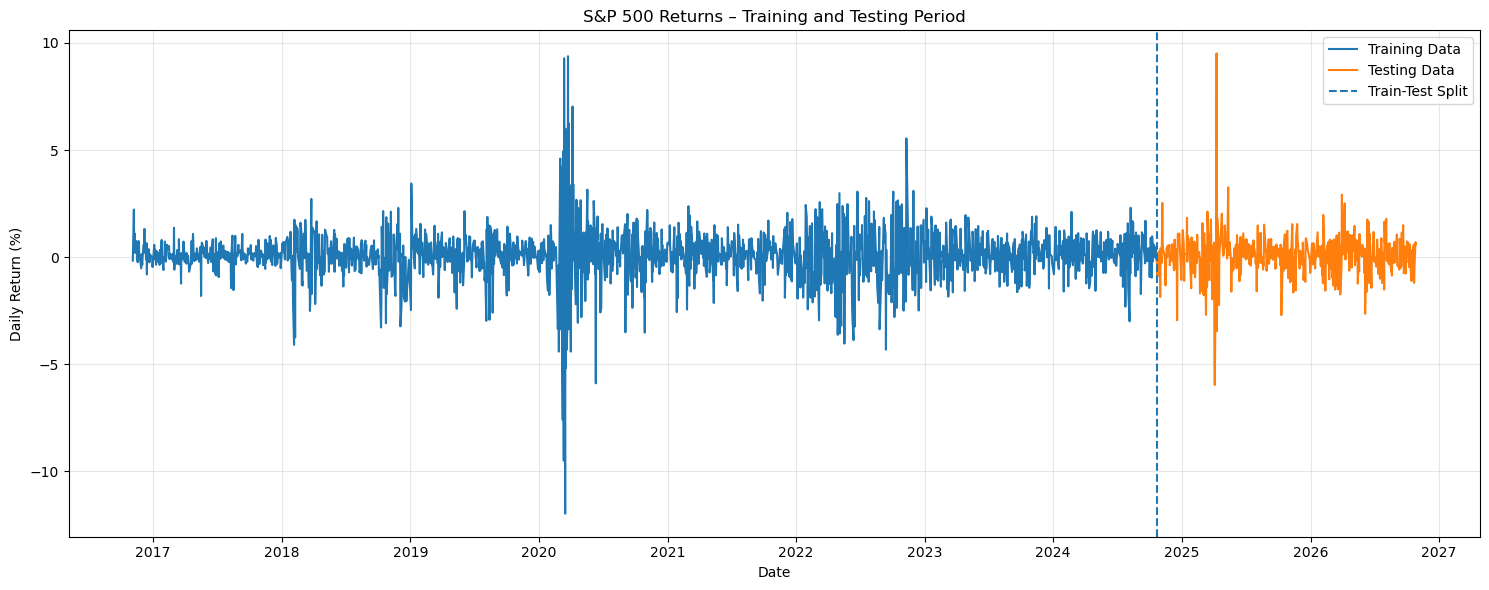

In [12]:
plt.figure(figsize=(15, 6))

plt.plot(train.index, train, label='Training Data')
plt.plot(test.index, test, label='Testing Data')

plt.axvline(
    x=test.index[0],
    linestyle='--',
    label='Train-Test Split'
)

plt.title('S&P 500 Returns – Training and Testing Period')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

A chronological train-test split was implemented to establish the training and evaluation datasets for ARIMA modelling.

The original dataset containing 2,320 observations was divided into 1,856 training observations (80%) and 464 testing observations (20%).

The training period extends from 4 November 2016 to 21 October 2024, while the testing period covers 22 October 2024 to 27 October 2026.

The chronological division preserves the temporal ordering of financial observations and prevents future information from entering the model estimation process. The training dataset will be used for model estimation and selection, while the testing dataset will remain reserved for evaluating out-of-sample forecasting performance.

The visualisation indicates that both periods contain substantial fluctuations in daily returns, including occasional extreme movements. The training period also incorporates the pronounced volatility observed around 2020, providing the model with exposure to an important historical market event.

Overall, the chronological split establishes an appropriate framework for evaluating the forecasting performance of candidate ARIMA models using previously unseen observations.

### ADDITIONAL ANALYSIS A5 (Phase 4 audit) — ADF on training sample only

In [13]:
# =====================================================================
# ADDITIONAL ANALYSIS A5 (Phase 4 audit) — ADF on training sample only
# Notebook: PHASE 3 | After Section 3.5 (train/test split cell)
# =====================================================================
import pandas as pd
from statsmodels.tsa.stattools import adfuller

def adf_row(series, label, **kw):
    r = adfuller(series, **kw)
    return {'Sample': label, 'ADF stat': r[0], 'p-value': r[1], 'Lags used': r[2],
            'Nobs': r[3], 'CV 1%': r[4]['1%'], 'CV 5%': r[4]['5%'], 'CV 10%': r[4]['10%']}

A5 = pd.DataFrame([
    adf_row(sp500_returns, 'Full sample (original spec: const, AIC lags)', regression='c', autolag='AIC'),
    adf_row(train,         'Training only (const, AIC lags)',              regression='c', autolag='AIC'),
    adf_row(train,         'Training only (const, BIC lags)',              regression='c', autolag='BIC'),
])
display(A5.round(4))

C:\Users\reshma begum\AppData\Local\Temp\ipykernel_17428\2455215133.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  r = adfuller(series, **kw)
C:\Users\reshma begum\AppData\Local\Temp\ipykernel_17428\2455215133.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  r = adfuller(series, **kw)
C:\Users\reshma begum\AppData\Local\Temp\ipykernel_17428\2455215133.py:9: Future

,Sample,ADF stat,p-value,Lags used,Nobs,CV 1%,CV 5%,CV 10%
0,"Full sample (original spec: const, AIC lags)",-11.5499,0.0000,23,2296,-3.4332,-2.8628,-2.5674
1,"Training only (const, AIC lags)",-9.8632,0.0000,24,1831,-3.4339,-2.8631,-2.5676
2,"Training only (const, BIC lags)",-13.4043,0.0000,8,1847,-3.4339,-2.8631,-2.5676


## 3.6 Candidate ARIMA Model Selection

In [14]:
# Define candidate ARIMA specifications

arima_orders = [
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2),
    (3, 0, 2)
]

# Store model results
arima_results = []

fitted_models = {}

# Estimate each candidate model
for order in arima_orders:

    try:
        model = ARIMA(
            train,
            order=order,
            trend='c'
        )

        fitted_model = model.fit()

        fitted_models[order] = fitted_model

        arima_results.append({
            'Model': f'ARIMA{order}',
            'AIC': fitted_model.aic,
            'BIC': fitted_model.bic,
            'Log_Likelihood': fitted_model.llf,
            'Converged': fitted_model.mle_retvals.get(
                'converged', True
            )
        })

        print(f'ARIMA{order} estimated successfully.')

    except Exception as e:
        print(f'ARIMA{order} failed: {e}')

# Create comparison table
arima_comparison = pd.DataFrame(arima_results)

arima_comparison = arima_comparison.sort_values(
    by='AIC'
).reset_index(drop=True)

display(arima_comparison.round(4))

C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


ARIMA(1, 0, 0) estimated successfully.
ARIMA(0, 0, 1) estimated successfully.


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., f

ARIMA(1, 0, 1) estimated successfully.


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


ARIMA(2, 0, 1) estimated successfully.


... (3 outputs left out)

ARIMA(2, 0, 2) estimated successfully.


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_par

ARIMA(3, 0, 2) estimated successfully.


,Model,AIC,BIC,Log_Likelihood,Converged
0,"ARIMA(2, 0, 2)",5734.5520,5767.7091,-2861.2760,True
1,"ARIMA(3, 0, 2)",5735.5077,5774.1910,-2860.7539,True
2,"ARIMA(1, 0, 2)",5834.1146,5861.7455,-2912.0573,True
3,"ARIMA(2, 0, 1)",5835.0640,5862.6949,-2912.5320,True
4,"ARIMA(1, 0, 1)",5835.9766,5858.0813,-2913.9883,True
5,"ARIMA(1, 0, 0)",5840.6692,5857.2477,-2917.3346,True
6,"ARIMA(0, 0, 1)",5847.8901,5864.4687,-2920.9451,True


### 3.6.1 Correcting the Time Index and Re-estimating Candidate Models

In [15]:
# Convert training observations to an integer-indexed series
train_model = pd.Series(
    train.to_numpy(),
    index=pd.RangeIndex(len(train)),
    name='SP500_Return'
)

# Define candidate ARIMA specifications
arima_orders = [
    (1, 0, 0),
    (0, 0, 1),
    (1, 0, 1),
    (2, 0, 1),
    (1, 0, 2),
    (2, 0, 2),
    (3, 0, 2)
]

arima_results = []
fitted_models = {}

# Estimate candidate models
for order in arima_orders:

    try:
        model = ARIMA(
            train_model,
            order=order,
            trend='c'
        )

        fitted_model = model.fit()

        fitted_models[order] = fitted_model

        arima_results.append({
            'Model': f'ARIMA{order}',
            'AIC': fitted_model.aic,
            'BIC': fitted_model.bic,
            'Log_Likelihood': fitted_model.llf,
            'Converged': fitted_model.mle_retvals.get(
                'converged', True
            )
        })

        print(f'ARIMA{order} estimated successfully.')

    except Exception as e:
        print(f'ARIMA{order} failed: {e}')

# Compare models
arima_comparison = pd.DataFrame(arima_results)

arima_comparison = arima_comparison.sort_values(
    by='AIC'
).reset_index(drop=True)

display(arima_comparison.round(4))

ARIMA(1, 0, 0) estimated successfully.
ARIMA(0, 0, 1) estimated successfully.
ARIMA(1, 0, 1) estimated successfully.
ARIMA(2, 0, 1) estimated successfully.
ARIMA(1, 0, 2) estimated successfully.
ARIMA(2, 0, 2) estimated successfully.


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA(3, 0, 2) estimated successfully.


,Model,AIC,BIC,Log_Likelihood,Converged
0,"ARIMA(2, 0, 2)",5734.5520,5767.7091,-2861.2760,True
1,"ARIMA(3, 0, 2)",5735.5077,5774.1910,-2860.7539,True
2,"ARIMA(1, 0, 2)",5834.1146,5861.7455,-2912.0573,True
3,"ARIMA(2, 0, 1)",5835.0640,5862.6949,-2912.5320,True
4,"ARIMA(1, 0, 1)",5835.9766,5858.0813,-2913.9883,True
5,"ARIMA(1, 0, 0)",5840.6692,5857.2477,-2917.3346,True
6,"ARIMA(0, 0, 1)",5847.8901,5864.4687,-2920.9451,True


### Interpretation

Seven candidate ARIMA specifications were estimated using the training dataset, with an integration order of d = 0 based on the results of the Augmented Dickey-Fuller test.

The models were compared using the Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC). Among the evaluated specifications, ARIMA(2,0,2) achieved the lowest AIC of 5734.5520 and the lowest BIC of 5767.7091.

ARIMA(3,0,2) produced a relatively similar AIC of 5735.5077. However, its higher BIC indicates that the additional autoregressive parameter does not provide sufficient improvement to justify the increased model complexity under this criterion.

Based on the combined AIC and BIC results, ARIMA(2,0,2) was selected as the leading candidate specification for further evaluation.

All seven candidate models reported successful convergence. However, the ARIMA(3,0,2) estimation generated initialisation warnings relating to its autoregressive and moving-average starting parameters. The model nevertheless converged successfully.

The selected specification will undergo further examination through parameter significance testing and residual diagnostics before its suitability for forecasting is assessed.

## 3.7 ARIMA Model Estimation

In [16]:
# Select ARIMA(2,0,2)

best_order = (2, 0, 2)

best_arima = ARIMA(
    train_model,
    order=best_order,
    trend='c'
).fit()

# Display model summary
print(best_arima.summary())

                               SARIMAX Results                                
Dep. Variable:           SP500_Return   No. Observations:                 1856
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -2861.276
Date:                Tue, 17 Nov 2026   AIC                           5734.552
Time:                        16:57:40   BIC                           5767.709
Sample:                             0   HQIC                          5746.773
                               - 1856                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0650      0.025      2.571      0.010       0.015       0.115
ar.L1         -1.7276      0.016   -108.321      0.000      -1.759      -1.696
ar.L2         -0.8685      0.015    -59.578      0.0

### Interpretation

The ARIMA(2,0,2) model was estimated using the training dataset containing 1,856 observations. The model was selected as the leading candidate based on its relatively low AIC and BIC values compared with the other evaluated specifications.

The estimated model contains two autoregressive components and two moving-average components. All four coefficients were statistically significant at the 5% significance level. The constant term was also statistically significant, with an estimated value of 0.0650.

The autoregressive coefficients indicate that previous return observations contribute to the estimated current returns, while the moving-average coefficients indicate that previous forecast errors also contribute to the model's estimation.

The initial residual diagnostics produced mixed results. The Ljung-Box test at lag 1 returned a p-value of 0.48, providing insufficient evidence of residual autocorrelation at that lag. However, this single-lag result is not sufficient to establish that the residuals are uncorrelated across multiple lags.

The Jarque-Bera test produced a statistic of 6813.09 with a p-value below 0.001, indicating a substantial departure from normality. The residual distribution also exhibited negative skewness of -0.85 and excess tail concentration, with reported kurtosis of 12.23.

Furthermore, the heteroskedasticity test produced a statistic of 2.14 with a p-value below 0.001, indicating that the residual variance is not constant.

Overall, ARIMA(2,0,2) provides a statistically significant representation of short-term return dynamics. However, the residual diagnostics indicate that non-normality and time-varying variance remain important limitations. Further residual analysis is therefore necessary before evaluating the model's forecasting performance.

### ADDITIONAL ANALYSI — Constant-only model + roots

In [17]:
# =====================================================================
# ADDITIONAL ANALYSIS A3 (Phase 4 audit) — Constant-only model + roots
# Notebook: PHASE 3 | After Section 3.7 | Requires train_model,
#           fitted_models, arima_comparison, best_arima
# =====================================================================
import numpy as np, pandas as pd
from statsmodels.tsa.arima.model import ARIMA

const_only = ARIMA(train_model, order=(0, 0, 0), trend='c').fit()
new_row = pd.DataFrame([{'Model': 'ARIMA(0, 0, 0) constant-only', 'AIC': const_only.aic,
                         'BIC': const_only.bic, 'Log_Likelihood': const_only.llf}])
A3_ic = pd.concat([arima_comparison[['Model', 'AIC', 'BIC', 'Log_Likelihood']], new_row],
                  ignore_index=True).sort_values('AIC').reset_index(drop=True)
display(A3_ic.round(4))
print("Constant-only estimate:", const_only.params.to_dict())

def get_roots(res):
    phi   = np.array([res.params[n] for n in res.params.index if n.startswith('ar.L')])
    theta = np.array([res.params[n] for n in res.params.index if n.startswith('ma.L')])
    ar_r = np.roots(np.r_[-phi[::-1], 1.0]) if len(phi)   else np.array([])
    ma_r = np.roots(np.r_[theta[::-1], 1.0]) if len(theta) else np.array([])
    return ar_r, ma_r

def root_detail(roots, kind):
    return pd.DataFrame({'Type': kind, 'Root': np.round(roots, 4),
                         'Modulus': np.abs(roots),
                         'Angle (deg)': np.degrees(np.angle(roots)),
                         'Cycle length (obs)': 2 * np.pi / np.abs(np.angle(roots))})

# Detail for the selected model
ar_r, ma_r = get_roots(best_arima)
display(pd.concat([root_detail(ar_r, 'AR'), root_detail(ma_r, 'MA')], ignore_index=True).round(4))
print("Stationary (all AR |root| > 1):", bool(np.all(np.abs(ar_r) > 1)))
print("Invertible (all MA |root| > 1):", bool(np.all(np.abs(ma_r) > 1)))
if len(ar_r) and len(ma_r):
    print("Nearest AR-MA root distance:", np.min(np.abs(ar_r[:, None] - ma_r[None, :])))

# Summary across all candidates
summary = []
for order, res in fitted_models.items():
    a, m = get_roots(res)
    summary.append({'Model': f'ARIMA{order}',
                    'Min |AR root|': np.abs(a).min() if len(a) else np.nan,
                    'Min |MA root|': np.abs(m).min() if len(m) else np.nan,
                    'Nearest AR-MA distance': np.min(np.abs(a[:, None] - m[None, :])) if len(a) and len(m) else np.nan})
display(pd.DataFrame(summary).round(4))

,Model,AIC,BIC,Log_Likelihood
0,"ARIMA(2, 0, 2)",5734.5520,5767.7091,-2861.2760
1,"ARIMA(3, 0, 2)",5735.5077,5774.1910,-2860.7539
2,"ARIMA(1, 0, 2)",5834.1146,5861.7455,-2912.0573
3,"ARIMA(2, 0, 1)",5835.0640,5862.6949,-2912.5320
4,"ARIMA(1, 0, 1)",5835.9766,5858.0813,-2913.9883
5,"ARIMA(1, 0, 0)",5840.6692,5857.2477,-2917.3346
6,"ARIMA(0, 0, 1)",5847.8901,5864.4687,-2920.9451
7,"ARIMA(0, 0, 0) constant-only",5889.6618,5900.7142,-2942.8309


Constant-only estimate: {'const': 0.06503288708550489, 'sigma2': 1.3955220260361996}


,Type,Root,Modulus,Angle (deg),Cycle length (obs)
0,AR,-0.9945+0.4029j,1.0730,157.9479,2.2792
1,AR,-0.9945-0.4029j,1.0730,-157.9479,2.2792
2,MA,-1.1112+0.3812j,1.1748,161.0668,2.2351
3,MA,-1.1112-0.3812j,1.1748,-161.0668,2.2351


Stationary (all AR |root| > 1): True
Invertible (all MA |root| > 1): True
Nearest AR-MA root distance: 0.11872832337696068


,Model,Min |AR root|,Min |MA root|,Nearest AR-MA distance
0,"ARIMA(1, 0, 0)",6.0758,NaN,NaN
1,"ARIMA(0, 0, 1)",NaN,7.0367,NaN
2,"ARIMA(1, 0, 1)",2.3855,3.8771,1.4916
3,"ARIMA(2, 0, 1)",2.8973,33.0966,28.6015
4,"ARIMA(1, 0, 2)",4.3364,3.8600,5.3498
5,"ARIMA(2, 0, 2)",1.0730,1.1748,0.1187
6,"ARIMA(3, 0, 2)",1.0763,1.1931,0.1327


## 3.8 ARIMA Residual Diagnostics

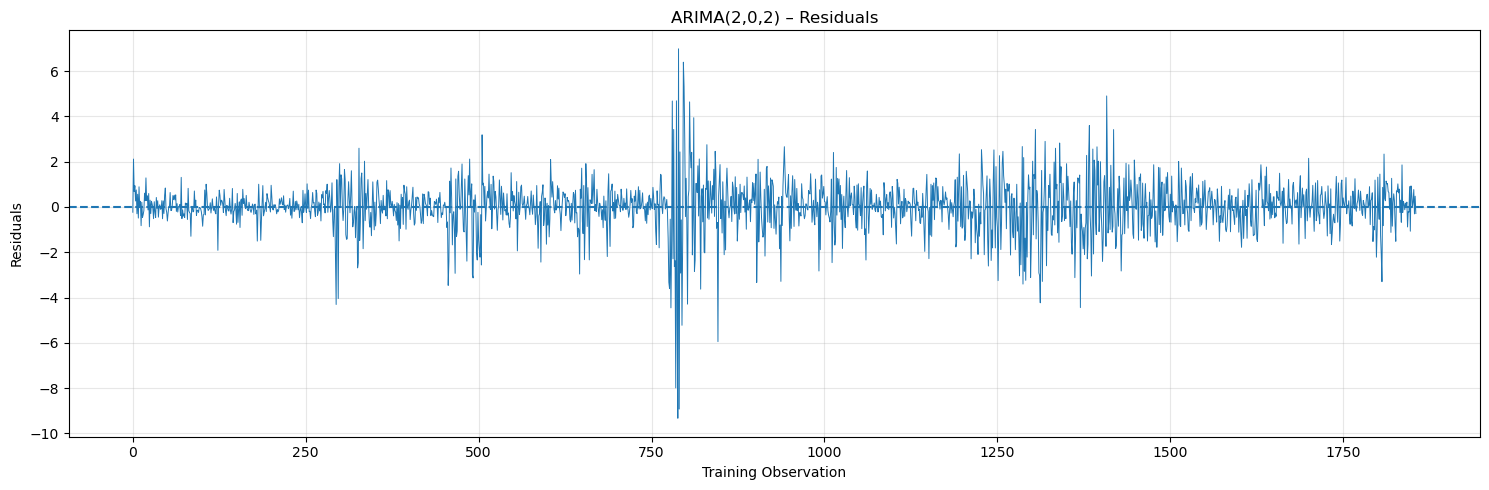

In [18]:
# Extract ARIMA residuals

arima_residuals = best_arima.resid

# Plot residuals over time
plt.figure(figsize=(15, 5))

plt.plot(arima_residuals, linewidth=0.7)

plt.axhline(y=0, linestyle='--')

plt.title('ARIMA(2,0,2) – Residuals')
plt.xlabel('Training Observation')
plt.ylabel('Residuals')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

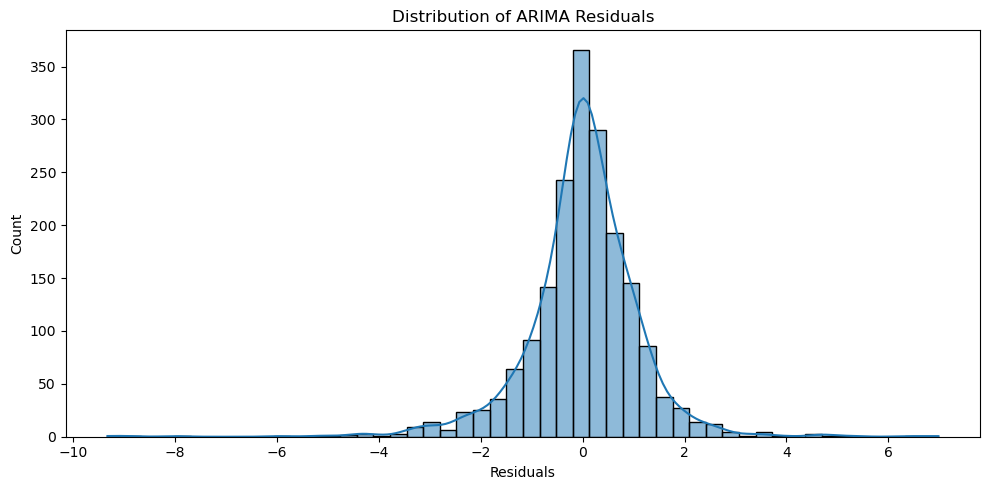

In [19]:
# Plot residual distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    arima_residuals,
    bins=50,
    kde=True
)

plt.title('Distribution of ARIMA Residuals')
plt.xlabel('Residuals')

plt.tight_layout()
plt.show()

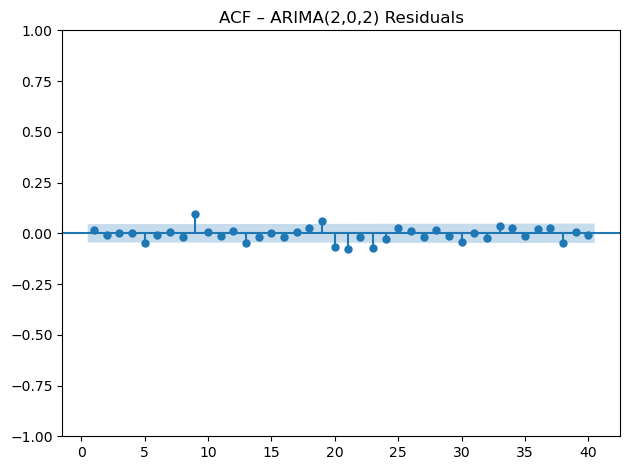

In [20]:
# Examine residual autocorrelation

plot_acf(
    arima_residuals,
    lags=40,
    zero=False
)

plt.title('ACF – ARIMA(2,0,2) Residuals')
plt.tight_layout()
plt.show()

### 3.8.1 Formal Residual Diagnostic Tests

In [21]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Ljung-Box test at multiple lags
ljung_box_results = acorr_ljungbox(
    arima_residuals,
    lags=[5, 10, 20],
    return_df=True
)

display(ljung_box_results.round(5))

,lb_stat,lb_pvalue
5,4.7554,0.4465
10,21.7857,0.0162
20,44.3214,0.0014


In [22]:
from statsmodels.stats.diagnostic import het_arch

# ARCH LM test
arch_test = het_arch(
    arima_residuals,
    nlags=10
)

print("ARCH LM Statistic:", arch_test[0])
print("ARCH LM p-value:", arch_test[1])
print("F Statistic:", arch_test[2])
print("F-test p-value:", arch_test[3])

ARCH LM Statistic: 613.1570932250941
ARCH LM p-value: 2.668514205612965e-125
F Statistic: 91.26412293772297
F-test p-value: 5.062680693493512e-153


C:\Users\reshma begum\anaconda3\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


### Preliminary Interpretation

The residual plots were examined to assess the adequacy of the ARIMA(2,0,2) model.

The residual time-series plot indicates that the residuals generally fluctuate around zero. However, several periods exhibit unusually large movements and concentrated volatility, suggesting that the residual variance may not remain constant over time.

The residual distribution is concentrated around zero but exhibits noticeable deviations from a normal distribution, including relatively heavy tails and extreme observations.

The residual ACF plot indicates that most autocorrelation coefficients fall within the 95% confidence bands, although a small number of isolated lags extend beyond them. This suggests that the ARIMA model captures much of the linear dependence in the training series, although further statistical testing is required to assess whether residual autocorrelation remains.

Formal Ljung-Box and ARCH LM tests will be used to investigate residual autocorrelation and conditional heteroskedasticity, respectively.

### Interpretation

Formal residual diagnostic tests were conducted to evaluate whether the ARIMA(2,0,2) model adequately captures the time-series characteristics of S&P 500 daily returns.

The Ljung-Box test was performed at lags 5, 10 and 20. At lag 5, the test produced a p-value of 0.4465, providing insufficient evidence to reject the null hypothesis of no residual autocorrelation. However, the p-values at lags 10 and 20 were 0.0162 and 0.0014, respectively. Both are below the 5% significance level, indicating that statistically significant residual autocorrelation remains at longer lag intervals.

The ARCH LM test produced a statistic of 613.1571 with a p-value of approximately 2.67 × 10⁻¹²⁵. Consequently, the null hypothesis of no ARCH effects is rejected. This provides strong statistical evidence that the residual variance is time-dependent and exhibits conditional heteroskedasticity.

These findings indicate that although ARIMA(2,0,2) captures some of the short-term linear dependence in S&P 500 returns, it does not fully account for the longer-term residual autocorrelation or volatility clustering.

The presence of significant ARCH effects is consistent with the volatility patterns identified during the exploratory time-series analysis.

Overall, the residual diagnostics highlight limitations in the ARIMA specification, particularly its inability to explicitly model time-varying conditional variance. The model will nevertheless be retained as a baseline forecasting specification. Its out-of-sample performance will be evaluated, and the potential benefits of an extended volatility model can be investigated separately.

## 3.9 Forecast Generation

In [23]:
# Generate forecasts for the testing period

forecast_result = best_arima.get_forecast(
    steps=len(test)
)

# Extract forecasted values
arima_forecast = forecast_result.predicted_mean

# Extract confidence intervals
forecast_conf_int = forecast_result.conf_int()

# Assign actual testing dates
arima_forecast.index = test.index
forecast_conf_int.index = test.index

print("Forecast observations:", len(arima_forecast))
print("Forecast period:", arima_forecast.index.min(),
      "to", arima_forecast.index.max())

display(arima_forecast.head())

Forecast observations: 464
Forecast period: 2024-10-22 00:00:00 to 2026-10-27 00:00:00


Date
2024-10-22   0.0828
2024-10-23   0.0397
2024-10-24   0.0935
2024-10-25   0.0380
2024-10-28   0.0871
Name: predicted_mean, dtype: float64

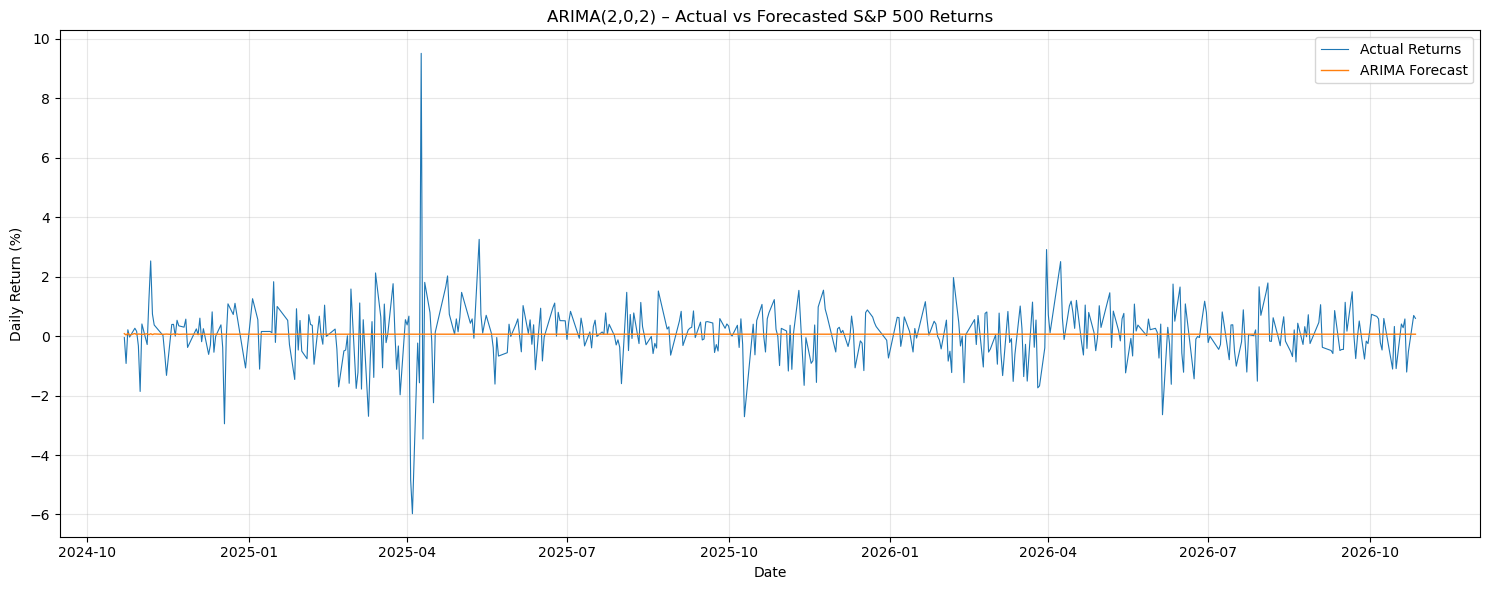

In [24]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label='Actual Returns',
    linewidth=0.8
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label='ARIMA Forecast',
    linewidth=1
)

plt.title('ARIMA(2,0,2) – Actual vs Forecasted S&P 500 Returns')
plt.xlabel('Date')
plt.ylabel('Daily Return (%)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

Out-of-sample forecasts were generated using the selected ARIMA(2,0,2) model for the 464 observations in the testing dataset, covering the period from 22 October 2024 to 27 October 2026.

The actual-versus-forecasted returns plot reveals that the ARIMA forecasts remain relatively close to the estimated mean return throughout the testing period. This behaviour occurs because multi-step ARIMA forecasts tend to converge towards the model's long-run mean as the forecasting horizon increases.

In contrast, actual S&P 500 returns exhibit substantial fluctuations, including several pronounced positive and negative movements. The model does not adequately capture the timing or magnitude of these extreme market movements.

The difference between the actual and forecasted series suggests that the model has limited ability to reproduce short-term fluctuations over an extended forecasting horizon. Although it provides forecasts of the conditional mean, it does not explicitly account for the time-varying volatility observed in financial returns.

Overall, the visual comparison indicates that ARIMA(2,0,2) produces relatively stable multi-step forecasts but struggles to capture the dynamic behaviour of daily S&P 500 returns. Its forecasting accuracy will be assessed quantitatively using out-of-sample evaluation metrics and benchmark comparisons.

In [25]:
# Calculate forecasting errors

mae = mean_absolute_error(
    test,
    arima_forecast
)

rmse = np.sqrt(
    mean_squared_error(
        test,
        arima_forecast
    )
)

mean_error = np.mean(
    test - arima_forecast
)

print("ARIMA(2,0,2) Forecast Evaluation")
print("--------------------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("Mean Error:", round(mean_error, 4))

ARIMA(2,0,2) Forecast Evaluation
--------------------------------
MAE: 0.6724
RMSE: 1.0197
Mean Error: 0.0047


In [26]:
# Zero-return benchmark

zero_forecast = pd.Series(
    0.0,
    index=test.index
)

zero_mae = mean_absolute_error(
    test,
    zero_forecast
)

zero_rmse = np.sqrt(
    mean_squared_error(
        test,
        zero_forecast
    )
)

zero_mean_error = np.mean(
    test - zero_forecast
)

print("Zero-Return Benchmark Evaluation")
print("--------------------------------")
print("MAE:", round(zero_mae, 4))
print("RMSE:", round(zero_rmse, 4))
print("Mean Error:", round(zero_mean_error, 4))

Zero-Return Benchmark Evaluation
--------------------------------
MAE: 0.6771
RMSE: 1.0221
Mean Error: 0.0698


In [27]:
# Compare ARIMA against zero-return benchmark

forecast_comparison = pd.DataFrame({
    'Model': [
        'ARIMA(2,0,2)',
        'Zero-Return Benchmark'
    ],
    'MAE': [
        mae,
        zero_mae
    ],
    'RMSE': [
        rmse,
        zero_rmse
    ],
    'Mean_Error': [
        mean_error,
        zero_mean_error
    ]
})

display(forecast_comparison.round(5))

,Model,MAE,RMSE,Mean_Error
0,"ARIMA(2,0,2)",0.6724,1.0197,0.0047
1,Zero-Return Benchmark,0.6771,1.0221,0.0698


### 3.10.1 Forecasting Performance Improvement

In [28]:
# Calculate percentage improvement over zero-return benchmark

mae_improvement = (
    (zero_mae - mae) / zero_mae
) * 100

rmse_improvement = (
    (zero_rmse - rmse) / zero_rmse
) * 100

print("MAE Improvement:", round(mae_improvement, 4), "%")
print("RMSE Improvement:", round(rmse_improvement, 4), "%")

MAE Improvement: 0.6866 %
RMSE Improvement: 0.2412 %


### Interpretation

The out-of-sample forecasting performance of ARIMA(2,0,2) was evaluated using 464 observations from the testing dataset. Its performance was compared against a zero-return benchmark, which assumes that the expected daily S&P 500 return is zero.

The ARIMA model achieved a Mean Absolute Error (MAE) of 0.6724 and a Root Mean Squared Error (RMSE) of 1.0197. The zero-return benchmark produced an MAE of 0.6771 and an RMSE of 1.0221.

Although ARIMA outperformed the benchmark on both evaluation metrics, the improvement was relatively small. The MAE decreased by approximately 0.69%, while the RMSE decreased by approximately 0.23%.

The ARIMA model also produced a mean forecasting error of 0.0047, compared with 0.0698 for the zero-return benchmark. This indicates that the ARIMA forecasts exhibited less average bias over the testing period.

Overall, ARIMA(2,0,2) demonstrated a marginal improvement over the zero-return benchmark. However, the relatively small reduction in forecasting errors suggests that the historical linear dependencies captured by the ARIMA model provide limited additional forecasting information.

These findings are consistent with the earlier residual diagnostics, which identified remaining autocorrelation and substantial ARCH effects. The model captures some aspects of the conditional mean but does not adequately represent the volatility dynamics of financial returns.

Consequently, although ARIMA(2,0,2) provides a statistically structured approach to forecasting daily returns, its practical forecasting advantage over a simple zero-return benchmark appears limited.

## 3.11 Statistical Comparison of Forecasting Performance

In [29]:
from scipy.stats import norm

# Calculate squared forecast errors
arima_errors = test - arima_forecast
benchmark_errors = test - zero_forecast

arima_loss = arima_errors ** 2
benchmark_loss = benchmark_errors ** 2

# Loss differential
loss_difference = benchmark_loss - arima_loss

# Diebold-Mariano statistic for equal forecast accuracy
dm_statistic = (
    loss_difference.mean()
    / (loss_difference.std(ddof=1) / np.sqrt(len(loss_difference)))
)

# Two-sided p-value
dm_p_value = 2 * norm.sf(abs(dm_statistic))

print("Diebold-Mariano Statistic:", dm_statistic)
print("P-value:", dm_p_value)

Diebold-Mariano Statistic: 0.8146281523872109
P-value: 0.41528519075476944


### Interpretation

The Diebold-Mariano test was conducted to investigate whether the forecasting performance of ARIMA(2,0,2) differed significantly from that of the zero-return benchmark.

The test produced a statistic of 0.8146 and a p-value of 0.4153. Since the p-value exceeds the 5% significance level, the null hypothesis of equal predictive accuracy cannot be rejected.

Although ARIMA(2,0,2) achieved marginally lower MAE and RMSE values than the zero-return benchmark, the Diebold-Mariano test does not provide sufficient statistical evidence that this improvement represents a significant forecasting advantage.

The results therefore suggest that the additional linear structure captured by the ARIMA model provides only limited improvements over a simple zero-return forecasting approach.

An important methodological limitation is that the comparison uses a single fixed-origin, multi-step forecasting exercise. The reported Diebold-Mariano statistic also uses an unadjusted variance estimate and does not account for potential serial dependence in forecast losses. Consequently, the result is treated as a preliminary comparison rather than definitive evidence of equal predictive accuracy.

Overall, the forecasting results indicate that ARIMA(2,0,2) offers a marginal numerical improvement over the zero-return benchmark, but its statistical forecasting advantage has not been established.

## 3.12 Rolling-Origin One-Step-Ahead Forecasting

In [30]:
# Store rolling forecasts
rolling_forecasts = []

# Start with the fitted training model
rolling_model = best_arima

# Sequential one-step-ahead forecasting
for actual_return in test:

    # Forecast the next observation
    next_forecast = rolling_model.forecast(steps=1)

    rolling_forecasts.append(float(next_forecast.iloc[0]))

    # Update model state using the actual observation
    rolling_model = rolling_model.append(
        [actual_return],
        refit=False
    )

# Convert forecasts into a Series with testing dates
rolling_forecast = pd.Series(
    rolling_forecasts,
    index=test.index,
    name='Rolling_ARIMA_Forecast'
)

print("Rolling forecasts generated:", len(rolling_forecast))
print("Forecast period:")
print(rolling_forecast.index.min(), "to",
      rolling_forecast.index.max())

display(rolling_forecast.head())

Rolling forecasts generated: 464
Forecast period:
2024-10-22 00:00:00 to 2026-10-27 00:00:00


Date
2024-10-22    0.0828
2024-10-23    0.0549
2024-10-24    0.2000
2024-10-25   -0.0208
2024-10-28    0.0951
Name: Rolling_ARIMA_Forecast, dtype: float64

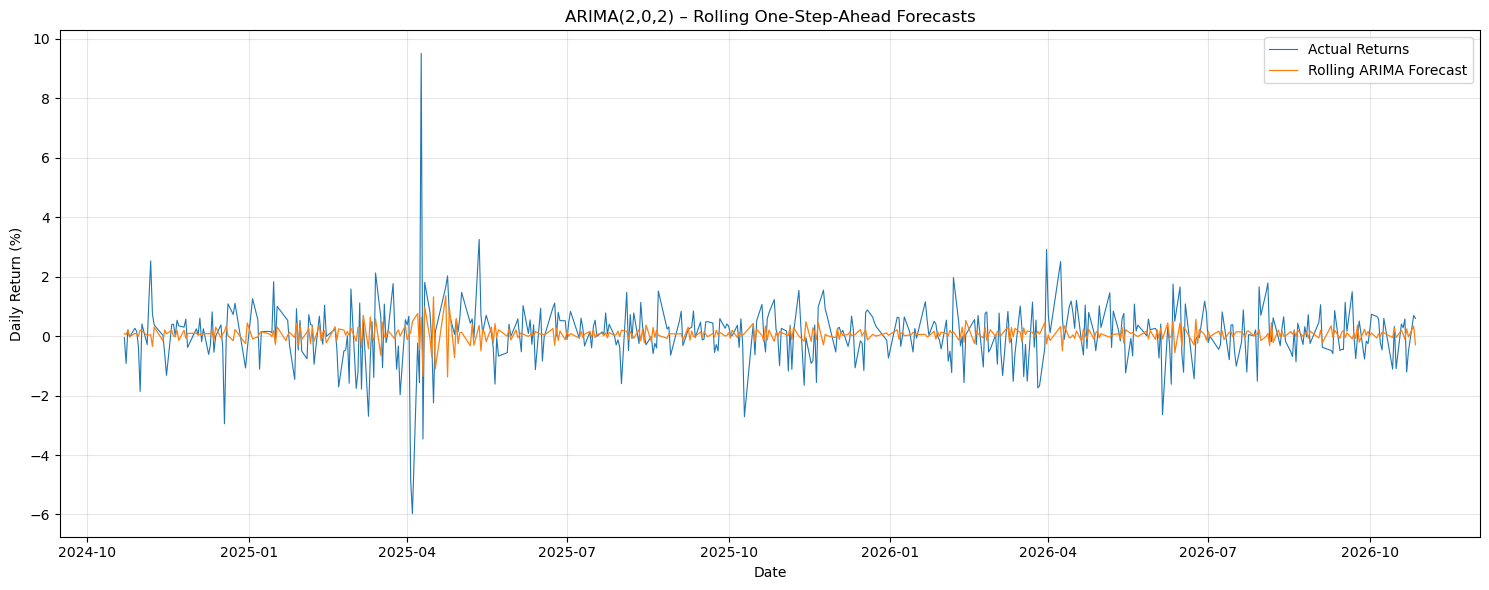

In [31]:
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label='Actual Returns',
    linewidth=0.8
)

plt.plot(
    rolling_forecast.index,
    rolling_forecast,
    label='Rolling ARIMA Forecast',
    linewidth=0.9
)

plt.title(
    'ARIMA(2,0,2) – Rolling One-Step-Ahead Forecasts'
)

plt.xlabel('Date')
plt.ylabel('Daily Return (%)')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation

A rolling-origin one-step-ahead forecasting approach was implemented to evaluate the ARIMA(2,0,2) model under a sequential forecasting framework.

Unlike the previous static forecasting approach, which generated all 464 predictions from a single fixed training endpoint, the rolling approach incorporated each newly observed testing-period return before generating the next forecast. The model parameters were kept fixed, while its internal state was updated sequentially using the actual observations.

The resulting forecasts exhibit greater responsiveness to incoming market information compared with the static multi-step forecasts. However, the predicted returns generally remain close to zero and do not adequately capture the magnitude of extreme market movements.

This suggests that although sequential updating allows the model to incorporate recent observations, its ability to anticipate substantial daily return fluctuations remains limited.

Overall, rolling-origin forecasting provides a more realistic evaluation of the model's one-step-ahead predictive performance. Quantitative comparison using forecasting error metrics is required to determine whether this approach provides a meaningful improvement over the static ARIMA forecasts and the zero-return benchmark.

### 3.12.3 Comparison of Static, Rolling and Benchmark Forecasts

In [32]:
# Calculate static ARIMA metrics

static_mae = mean_absolute_error(test, arima_forecast)

static_rmse = np.sqrt(
    mean_squared_error(test, arima_forecast)
)

static_mean_error = np.mean(test - arima_forecast)


# Calculate rolling ARIMA metrics

rolling_mae = mean_absolute_error(test, rolling_forecast)

rolling_rmse = np.sqrt(
    mean_squared_error(test, rolling_forecast)
)

rolling_mean_error = np.mean(test - rolling_forecast)


# Calculate zero-return benchmark metrics

benchmark_mae = mean_absolute_error(test, zero_forecast)

benchmark_rmse = np.sqrt(
    mean_squared_error(test, zero_forecast)
)

benchmark_mean_error = np.mean(test - zero_forecast)


# Create comparison table

forecast_comparison = pd.DataFrame({
    'Model': [
        'Static ARIMA(2,0,2)',
        'Rolling ARIMA(2,0,2)',
        'Zero-Return Benchmark'
    ],
    'MAE': [
        static_mae,
        rolling_mae,
        benchmark_mae
    ],
    'RMSE': [
        static_rmse,
        rolling_rmse,
        benchmark_rmse
    ],
    'Mean_Error': [
        static_mean_error,
        rolling_mean_error,
        benchmark_mean_error
    ]
})

display(forecast_comparison.round(5))

,Model,MAE,RMSE,Mean_Error
0,"Static ARIMA(2,0,2)",0.6724,1.0197,0.0047
1,"Rolling ARIMA(2,0,2)",0.6891,1.0273,0.0053
2,Zero-Return Benchmark,0.6771,1.0221,0.0698


In [33]:
# Calculate percentage improvement over benchmark

comparison_improvements = pd.DataFrame({
    'Model': [
        'Static ARIMA(2,0,2)',
        'Rolling ARIMA(2,0,2)'
    ],
    'MAE_Improvement_Percent': [
        (benchmark_mae - static_mae) / benchmark_mae * 100,
        (benchmark_mae - rolling_mae) / benchmark_mae * 100
    ],
    'RMSE_Improvement_Percent': [
        (benchmark_rmse - static_rmse) / benchmark_rmse * 100,
        (benchmark_rmse - rolling_rmse) / benchmark_rmse * 100
    ]
})

display(comparison_improvements.round(4))

,Model,MAE_Improvement_Percent,RMSE_Improvement_Percent
0,"Static ARIMA(2,0,2)",0.6866,0.2412
1,"Rolling ARIMA(2,0,2)",-1.7808,-0.5010


### Interpretation

The forecasting performance of static ARIMA(2,0,2), rolling-origin ARIMA(2,0,2) and the zero-return benchmark was compared using MAE, RMSE and mean forecasting error.

The static ARIMA model achieved the lowest MAE of 0.6724 and RMSE of 1.0197. The zero-return benchmark produced an MAE of 0.6771 and RMSE of 1.0221. Consequently, the static ARIMA model demonstrated marginal improvements of approximately 0.69% in MAE and 0.24% in RMSE.

In contrast, the rolling-origin ARIMA model produced an MAE of 0.6891 and RMSE of 1.0273. These values were higher than those of the zero-return benchmark, indicating that sequentially updating the model's internal state did not improve its forecasting accuracy over the testing period.

The mean forecasting errors were 0.0047 for static ARIMA, 0.0053 for rolling ARIMA and 0.0698 for the zero-return benchmark. Both ARIMA approaches therefore exhibited lower average forecasting bias, although this did not translate into better overall accuracy for the rolling specification.

An important methodological consideration is that static and rolling forecasts represent different forecasting horizons. Static ARIMA generates multi-step forecasts from a fixed origin, whereas rolling ARIMA generates sequential one-step-ahead forecasts. Their evaluation metrics are therefore not directly equivalent measures of forecasting performance.

Overall, the results indicate that the static ARIMA model provides a marginal numerical improvement over the zero-return benchmark, while the rolling-origin implementation does not demonstrate a similar improvement. These findings suggest that the short-term linear structure captured by the ARIMA specification provides limited practical forecasting information for daily S&P 500 returns.

### 3.12.1 Statistical Comparison of Rolling Forecast Accuracy

In [34]:
import statsmodels.api as sm

# Calculate squared forecast errors
rolling_errors = test - rolling_forecast
benchmark_errors = test - zero_forecast

# Calculate squared losses
rolling_loss = rolling_errors ** 2
benchmark_loss = benchmark_errors ** 2

# Positive values favour rolling ARIMA
loss_difference = benchmark_loss - rolling_loss

# Estimate mean loss difference with HAC standard errors
X = np.ones((len(loss_difference), 1))

dm_model = sm.OLS(
    loss_difference.to_numpy(),
    X
).fit(
    cov_type='HAC',
    cov_kwds={'maxlags': 5}
)

dm_statistic = dm_model.tvalues[0]
dm_p_value = dm_model.pvalues[0]

print("HAC-adjusted Diebold-Mariano-style Test")
print("---------------------------------------")
print("Test Statistic:", dm_statistic)
print("P-value:", dm_p_value)
print("Mean Loss Difference:", loss_difference.mean())

HAC-adjusted Diebold-Mariano-style Test
---------------------------------------
Test Statistic: -0.2263938390891074
P-value: 0.8208951192477125
Mean Loss Difference: -0.010494562014677009


### Interpretation

A HAC-adjusted Diebold-Mariano-style test was conducted to compare the out-of-sample forecasting accuracy of rolling-origin ARIMA(2,0,2) against the zero-return benchmark.

The test produced a statistic of -0.2264 and a p-value of 0.8209. Since the p-value exceeds the 5% significance level, the null hypothesis of equal predictive accuracy cannot be rejected.

The mean loss difference was -0.0105, indicating that the rolling ARIMA model produced a slightly higher average squared forecasting loss than the zero-return benchmark over the testing period.

These findings are consistent with the earlier evaluation metrics, where rolling ARIMA recorded higher MAE and RMSE values than the benchmark.

Overall, there is insufficient statistical evidence that rolling-origin ARIMA(2,0,2) provides a forecasting advantage over the zero-return benchmark. The results suggest that incorporating recent observations through sequential model updates does not necessarily improve the prediction of daily S&P 500 returns.

The statistical comparison uses a Newey-West HAC variance estimate with five lags to account for potential serial dependence in the loss differential. Nevertheless, the result should be interpreted as evidence from the specified testing period and model configuration rather than a general conclusion about all ARIMA forecasting approaches.

### Overall Forecasting Conclusions

The forecasting analysis evaluated the ability of historical S&P 500 daily returns to predict future market movements using ARIMA modelling.

Following stationarity testing and ACF/PACF analysis, seven candidate ARIMA specifications were estimated. ARIMA(2,0,2) was selected as the leading specification based on its comparatively low AIC and BIC values.

The selected model was evaluated using a chronological training and testing framework, with 1,856 observations used for model estimation and 464 observations reserved for out-of-sample evaluation.

Two forecasting approaches were investigated: static multi-step forecasting and rolling-origin one-step-ahead forecasting.

The static ARIMA model achieved an MAE of 0.6724 and an RMSE of 1.0197, marginally outperforming the zero-return benchmark, which recorded an MAE of 0.6771 and an RMSE of 1.0221. The corresponding improvements were approximately 0.69% in MAE and 0.24% in RMSE.

However, the rolling-origin ARIMA model produced an MAE of 0.6891 and an RMSE of 1.0273, performing worse than the zero-return benchmark. This indicates that sequentially incorporating newly observed returns did not improve forecasting accuracy under the selected model specification.

The preliminary Diebold-Mariano comparison for static forecasts did not establish a statistically significant difference in predictive accuracy. Similarly, the HAC-adjusted comparison between rolling ARIMA and the zero-return benchmark produced a p-value of 0.8209, providing insufficient evidence of a significant forecasting difference.

Residual diagnostics also identified significant autocorrelation at longer lags, substantial ARCH effects and deviations from normality. These findings indicate that the ARIMA specification does not fully capture the complex statistical characteristics of financial returns, particularly their time-varying volatility.

Overall, the findings suggest that historical daily S&P 500 returns contain limited linear information that can be exploited by the selected ARIMA model for forecasting. Although static ARIMA produced a marginal numerical improvement over the zero-return benchmark, a statistically significant forecasting advantage was not established.

Consequently, the forecasting analysis demonstrates the difficulty of predicting daily equity market returns using historical returns alone. Further investigation using volatility models, additional financial indicators and alternative forecasting methodologies could provide opportunities for improving predictive performance.

### ADDITIONAL ANALYSIS — Mean-based benchmarks

In [35]:
# =====================================================================
# ADDITIONAL ANALYSIS — Mean-based benchmarks
# =====================================================================

hist_mean_fc = pd.Series(train.mean(), index=test.index)           # fixed training mean
exp_mean_fc  = sp500_returns.expanding().mean().shift(1).loc[test.index]  # mean of all data before each test day

def fc_metrics(actual, forecast):
    err = actual - forecast
    return {'MAE': err.abs().mean(), 'RMSE': np.sqrt((err**2).mean()),
            'MSE': (err**2).mean(), 'Mean_Error': err.mean()}

forecasts = {
    'Zero-return':          zero_forecast,
    'Historical mean':      hist_mean_fc,
    'Expanding mean':       exp_mean_fc,
    'Static ARIMA(2,0,2)':  arima_forecast,
    'Rolling ARIMA(2,0,2)': rolling_forecast,
}
rows = {name: fc_metrics(test, f) for name, f in forecasts.items()}
A1 = pd.DataFrame(rows).T
for b in ['Zero-return', 'Expanding mean']:
    A1[f'MAE_gain_vs_{b} (%)']  = (A1.loc[b, 'MAE']  - A1['MAE'])  / A1.loc[b, 'MAE']  * 100
    A1[f'RMSE_gain_vs_{b} (%)'] = (A1.loc[b, 'RMSE'] - A1['RMSE']) / A1.loc[b, 'RMSE'] * 100
    A1[f'OOS_R2_vs_{b} (%)']    = (1 - A1['MSE'] / A1.loc[b, 'MSE']) * 100
display(A1.round(4))

# How quickly does the static ARIMA forecast converge to its own constant?
const = best_arima.params['const']
diff = np.abs(arima_forecast.to_numpy() - const)
not_conv = np.where(diff >= 0.001)[0]
h_conv = (not_conv.max() + 2) if len(not_conv) else 1
print("Training mean:", train.mean(), "| ARIMA constant:", const)
print("Static forecast stays within 0.001 of the constant from step:", h_conv, "of", len(test))

,MAE,RMSE,MSE,Mean_Error,MAE_gain_vs_Zero-return (%),RMSE_gain_vs_Zero-return (%),OOS_R2_vs_Zero-return (%),MAE_gain_vs_Expanding mean (%),RMSE_gain_vs_Expanding mean (%),OOS_R2_vs_Expanding mean (%)
Zero-return,0.6771,1.0221,1.0448,0.0698,0.0000,0.0000,0.0000,-0.6322,-0.2082,-0.4169
Historical mean,0.6726,1.0198,1.0399,0.0047,0.6626,0.2322,0.4638,0.0346,0.0244,0.0489
Expanding mean,0.6728,1.0200,1.0404,0.0050,0.6282,0.2078,0.4151,0.0000,0.0000,0.0000
"Static ARIMA(2,0,2)",0.6724,1.0197,1.0397,0.0047,0.6866,0.2412,0.4817,0.0588,0.0334,0.0669
"Rolling ARIMA(2,0,2)",0.6891,1.0273,1.0553,0.0053,-1.7808,-0.5010,-1.0045,-2.4242,-0.7103,-1.4255


Training mean: 0.06503788467772544 | ARIMA constant: 0.065044651621462
Static forecast stays within 0.001 of the constant from step: 47 of 464


In [36]:
# =====================================================================
# ADDITIONAL ANALYSIS A4 (Phase 4 audit) — HAC loss-differential tests
# Notebook: PHASE 3 | After A1 | Requires 'forecasts' dict from A1
# =====================================================================

def hac_loss_test(loss_bench, loss_model, maxlags):
    d = (loss_bench - loss_model).to_numpy()
    fit = sm.OLS(d, np.ones((len(d), 1))).fit(cov_type='HAC', cov_kwds={'maxlags': maxlags})
    return d.mean(), fit.tvalues[0], fit.pvalues[0]

losses = {'squared':  lambda e: e ** 2, 'absolute': lambda e: e.abs()}
benchmarks = ['Zero-return', 'Expanding mean', 'Historical mean']
models = ['Static ARIMA(2,0,2)', 'Rolling ARIMA(2,0,2)']
primary_b = {'Zero-return', 'Expanding mean'}

rows = []
for L in [5, 10, 20]:
    for b in benchmarks:
        for m in models:
            for lname, lf in losses.items():
                md, t, p = hac_loss_test(lf(test - forecasts[b]), lf(test - forecasts[m]), L)
                rows.append({'Benchmark': b, 'Model': m, 'Loss': lname, 'HAC lags': L,
                             'Mean loss diff (bench - model)': md, 't-stat': t, 'p-value': p,
                             'Primary': (L == 5 and b in primary_b)})
A4 = pd.DataFrame(rows)
display(A4[A4['Primary']].round(4))
display(A4[~A4['Primary']].round(4))

,Benchmark,Model,Loss,HAC lags,Mean loss diff (bench - model),t-stat,p-value,Primary
0,Zero-return,"Static ARIMA(2,0,2)",squared,5,0.0050,0.8958,0.3703,True
1,Zero-return,"Static ARIMA(2,0,2)",absolute,5,0.0046,1.6659,0.0957,True
2,Zero-return,"Rolling ARIMA(2,0,2)",squared,5,-0.0105,-0.2264,0.8209,True
3,Zero-return,"Rolling ARIMA(2,0,2)",absolute,5,-0.0121,-1.2038,0.2287,True
4,Expanding mean,"Static ARIMA(2,0,2)",squared,5,0.0007,1.7341,0.0829,True
5,Expanding mean,"Static ARIMA(2,0,2)",absolute,5,0.0004,1.9781,0.0479,True
6,Expanding mean,"Rolling ARIMA(2,0,2)",squared,5,-0.0148,-0.3221,0.7474,True
7,Expanding mean,"Rolling ARIMA(2,0,2)",absolute,5,-0.0163,-1.6265,0.1038,True


,Benchmark,Model,Loss,HAC lags,Mean loss diff (bench - model),t-stat,p-value,Primary
8,Historical mean,"Static ARIMA(2,0,2)",squared,5,0.0002,1.1825,0.2370,False
9,Historical mean,"Static ARIMA(2,0,2)",absolute,5,0.0002,0.9240,0.3555,False
10,Historical mean,"Rolling ARIMA(2,0,2)",squared,5,-0.0153,-0.3344,0.7381,False
11,Historical mean,"Rolling ARIMA(2,0,2)",absolute,5,-0.0165,-1.6448,0.1000,False
12,Zero-return,"Static ARIMA(2,0,2)",squared,10,0.0050,0.9159,0.3597,False
13,Zero-return,"Static ARIMA(2,0,2)",absolute,10,0.0046,1.6573,0.0975,False
14,Zero-return,"Rolling ARIMA(2,0,2)",squared,10,-0.0105,-0.3111,0.7557,False
15,Zero-return,"Rolling ARIMA(2,0,2)",absolute,10,-0.0121,-1.3147,0.1886,False
16,Expanding mean,"Static ARIMA(2,0,2)",squared,10,0.0007,1.9672,0.0492,False
17,Expanding mean,"Static ARIMA(2,0,2)",absolute,10,0.0004,2.1813,0.0292,False


### 3.13.1 Limitations of the Forecasting Model
### Limitations

Several limitations should be considered when interpreting the forecasting results.

**1. Limited Predictive Information in Historical Returns**

Daily S&P 500 returns exhibit relatively weak linear dependence on their historical values. Consequently, ARIMA modelling provides limited forecasting improvements over the zero-return benchmark.

**2. Time-Varying Volatility**

The residual ARCH test identified substantial conditional heteroskedasticity. The ARIMA model primarily captures conditional mean dynamics and does not explicitly model time-varying conditional variance.

**3. Extreme Market Movements**

The model struggles to predict unusually large positive and negative daily returns. Such movements may be associated with unexpected economic announcements, geopolitical developments and financial market shocks.

**4. Model Specification**

The analysis examined a limited set of candidate ARIMA specifications. Other statistical and machine-learning approaches may capture additional patterns not represented by the selected model.

**5. Forecasting Framework**

The static and rolling forecasting approaches represent different forecasting horizons and should not be treated as directly equivalent experiments. The rolling evaluation also retained fixed model parameters rather than re-estimating them at every observation.

**6. Testing Period Dependence**

The evaluation was conducted over a specific testing period from October 2024 to October 2026. Forecasting performance may differ across other market conditions and historical periods.

Overall, these limitations indicate that the results should be interpreted within the context of the selected dataset, model specifications and evaluation period.

### ADDITIONAL ANALYSIS A6 (Phase 4 audit) — Gap diagnostics

In [37]:
# =====================================================================
# ADDITIONAL ANALYSIS A6 (Phase 4 audit) — Gap diagnostics
# Notebook: PHASE 3 | After Section 3.12.3 | Requires df, train, test,
#           rolling_forecast, zero_forecast
# =====================================================================
import numpy as np, pandas as pd

idx = df.index
bd_gap = np.array([np.busday_count(a.date(), b.date()) for a, b in zip(idx[:-1], idx[1:])])
print("Weekday step between adjacent observations (1 = consecutive weekday):")
print(pd.Series(bd_gap).value_counts().sort_index())
gap_flag = pd.Series(np.r_[False, bd_gap > 1], index=idx)
print("Observations following a hole - train:", gap_flag.loc[train.index].sum(),
      "| test:", gap_flag.loc[test.index].sum())

print("\nObservations per calendar year:")
print(df.groupby(df.index.year).size())
span = lambda s: np.busday_count(s.index.min().date(), (s.index.max() + pd.Timedelta(days=1)).date())
print("\nTrain obs / weekdays in span:", len(train), span(train))
print("Test  obs / weekdays in span:", len(test), span(test))

gf = gap_flag.loc[test.index]
e_roll, e_zero = test - rolling_forecast, test - zero_forecast
by_gap = pd.DataFrame({
    'n': gf.groupby(gf).size(),
    'Rolling_MAE':  e_roll.abs().groupby(gf).mean(),
    'Rolling_RMSE': e_roll.pow(2).groupby(gf).mean().pow(0.5),
    'Zero_MAE':     e_zero.abs().groupby(gf).mean(),
    'Zero_RMSE':    e_zero.pow(2).groupby(gf).mean().pow(0.5)})
by_gap.index = by_gap.index.map({False: 'Consecutive weekday', True: 'Follows a hole'})
display(by_gap.round(4))

Weekday step between adjacent observations (1 = consecutive weekday):
1    2187
3     115
4      15
5       2
Name: count, dtype: int64
Observations following a hole - train: 103 | test: 29

Observations per calendar year:
Date
2016     34
2017    239
2018    231
2019    239
2020    235
2021    232
2022    228
2023    230
2024    232
2025    229
2026    191
dtype: int64

Train obs / weekdays in span: 1856 2077
Test  obs / weekdays in span: 464 526


,n,Rolling_MAE,Rolling_RMSE,Zero_MAE,Zero_RMSE
Consecutive weekday,435,0.6912,1.0388,0.6739,1.0276
Follows a hole,29,0.6576,0.8353,0.7256,0.9357


In [38]:
# =====================================================================
# ADDITIONAL ANALYSIS L1 (Phase 4) — Lagged-indicator regression (minimal)
# Notebook: PHASE 3 | New final section | Requires A1 and A4 cells run first
# =====================================================================
import numpy as np, pandas as pd, statsmodels.api as sm

pred_cols = ['VIX_Change', 'Treasury_10Y_Change', 'Brent_Oil_Return', 'Fed_Rate_Change']
assert set(pred_cols) <= set(df.columns)

X_lag = df[pred_cols].shift(1)                 # indicators at the previous observation
tr_idx = train.index[1:]                       # first training obs has no lag
X_tr = sm.add_constant(X_lag.loc[tr_idx]);  y_tr = train.loc[tr_idx]
X_te = sm.add_constant(X_lag.loc[test.index], has_constant='add')
assert not X_te.isna().any().any() and X_te.index.equals(test.index)

# Estimation on training window only (HAC, 5 lags, for coefficient inference)
l1_fit = sm.OLS(y_tr, X_tr).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
print(l1_fit.summary())
print("Joint HAC Wald test, all four slopes = 0:")
print(l1_fit.wald_test(np.eye(5)[1:], use_f=False))
print("Training R2:", round(l1_fit.rsquared, 5), "| adj R2:", round(l1_fit.rsquared_adj, 5))

# One-step forecasts with FIXED parameters
l1_fc = pd.Series(l1_fit.predict(X_te), index=test.index)
forecasts_L1 = dict(forecasts)
forecasts_L1['Lagged-indicator OLS (fixed)'] = l1_fc

L1 = pd.DataFrame({k: fc_metrics(test, v) for k, v in forecasts_L1.items()}).T
for b in ['Zero-return', 'Expanding mean']:
    L1[f'MAE_gain_vs_{b} (%)']  = (L1.loc[b, 'MAE']  - L1['MAE'])  / L1.loc[b, 'MAE']  * 100
    L1[f'RMSE_gain_vs_{b} (%)'] = (L1.loc[b, 'RMSE'] - L1['RMSE']) / L1.loc[b, 'RMSE'] * 100
    L1[f'OOS_R2_vs_{b} (%)']    = (1 - L1['MSE'] / L1.loc[b, 'MSE']) * 100
display(L1.round(4))

# HAC loss-differential tests (primary: Zero and Expanding mean, 5 lags; Historical mean = sensitivity)
rows = []
for b in ['Zero-return', 'Expanding mean', 'Historical mean']:
    for lname, lf in losses.items():
        md, t, p = hac_loss_test(lf(test - forecasts_L1[b]),
                                 lf(test - forecasts_L1['Lagged-indicator OLS (fixed)']), 5)
        rows.append({'Benchmark': b, 'Loss': lname, 'Mean loss diff (bench - model)': md,
                     't-stat': t, 'p-value': p, 'Primary': b != 'Historical mean'})
display(pd.DataFrame(rows).round(4))

# REFERENCE ONLY (not a forecast; uses same-day indicators): Phase 2 specification refit on training window
Xc_tr = sm.add_constant(df.loc[train.index, pred_cols])
Xc_te = sm.add_constant(df.loc[test.index, pred_cols], has_constant='add')
c_fit = sm.OLS(train, Xc_tr).fit()
c_pred = pd.Series(c_fit.predict(Xc_te), index=test.index)
mse_c = ((test - c_pred) ** 2).mean()
print("Contemporaneous reference: training R2 =", round(c_fit.rsquared, 4),
      "| test-period OOS R2 vs expanding mean (%):",
      round((1 - mse_c / L1.loc['Expanding mean', 'MSE']) * 100, 2))

                            OLS Regression Results                            
Dep. Variable:           SP500_Return   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.025
Method:                 Least Squares   F-statistic:                    0.8494
Date:                Tue, 17 Nov 2026   Prob (F-statistic):              0.494
Time:                        16:57:52   Log-Likelihood:                -2916.4
No. Observations:                1855   AIC:                             5843.
Df Residuals:                    1850   BIC:                             5870.
Df Model:                           4                                         
Covariance Type:                  HAC                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.0690    

,MAE,RMSE,MSE,Mean_Error,MAE_gain_vs_Zero-return (%),RMSE_gain_vs_Zero-return (%),OOS_R2_vs_Zero-return (%),MAE_gain_vs_Expanding mean (%),RMSE_gain_vs_Expanding mean (%),OOS_R2_vs_Expanding mean (%)
Zero-return,0.6771,1.0221,1.0448,0.0698,0.0000,0.0000,0.0000,-0.6322,-0.2082,-0.4169
Historical mean,0.6726,1.0198,1.0399,0.0047,0.6626,0.2322,0.4638,0.0346,0.0244,0.0489
Expanding mean,0.6728,1.0200,1.0404,0.0050,0.6282,0.2078,0.4151,0.0000,0.0000,0.0000
"Static ARIMA(2,0,2)",0.6724,1.0197,1.0397,0.0047,0.6866,0.2412,0.4817,0.0588,0.0334,0.0669
"Rolling ARIMA(2,0,2)",0.6891,1.0273,1.0553,0.0053,-1.7808,-0.5010,-1.0045,-2.4242,-0.7103,-1.4255
Lagged-indicator OLS (fixed),0.6854,1.0258,1.0522,0.0025,-1.2222,-0.3564,-0.7140,-1.8621,-0.5653,-1.1339


,Benchmark,Loss,Mean loss diff (bench - model),t-stat,p-value,Primary
0,Zero-return,squared,-0.0075,-0.1929,0.8471,True
1,Zero-return,absolute,-0.0083,-0.9640,0.3351,True
2,Expanding mean,squared,-0.0118,-0.3173,0.7510,True
3,Expanding mean,absolute,-0.0125,-1.4726,0.1409,True
4,Historical mean,squared,-0.0123,-0.3332,0.7390,False
5,Historical mean,absolute,-0.0128,-1.4988,0.1339,False


Contemporaneous reference: training R2 = 0.5982 | test-period OOS R2 vs expanding mean (%): 75.08


In [39]:
# =====================================================================
# ROBUSTNESS R1 (Phase 4) — S&P-calendar univariate ARIMA
# Notebook: PHASE 3 | New final section | Primary results remain the cleaned-sample analysis
# =====================================================================
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA

RAW_PATH = PROJECT_ROOT / "Data" / "Raw" / "Financial_dataset_Raw.csv"

raw = pd.read_csv(RAW_PATH, parse_dates=['Date']).sort_values('Date')
sp = raw[['Date', 'SP500_Close']].dropna().reset_index(drop=True)
sp['Return'] = sp['SP500_Close'].pct_change() * 100
sp_ret = sp.dropna().set_index('Date')['Return']

cut = train.index.max()                                   # same calendar cut-off as the original
tr_s = sp_ret.loc[:cut]
te_s = sp_ret.loc[cut + pd.Timedelta(days=1):]
common = te_s.index.intersection(test.index)
print("R1 train obs:", len(tr_s), "| R1 test obs:", len(te_s), "| original test obs:", len(test))
print("Original test dates missing from R1 test:", len(test.index.difference(te_s.index)))
print("Extra R1 test dates (valid S&P days excluded originally):", len(te_s.index.difference(test.index)))
print("Returns identical on common dates:", np.allclose(te_s.loc[common].to_numpy(), test.loc[common].to_numpy()))

# Same ARIMA(2,0,2) specification, re-estimated on the R1 training sample (no re-selection)
r1_fit = ARIMA(pd.Series(tr_s.to_numpy()), order=(2, 0, 2), trend='c').fit()
print(r1_fit.summary())
display(pd.DataFrame({'Original (cleaned sample)': best_arima.params,
                      'R1 (S&P calendar)': r1_fit.params}).round(4))
print("AIC/BIC are NOT comparable across samples. R1 AIC/BIC:", round(r1_fit.aic, 2), round(r1_fit.bic, 2))
a_r, m_r = get_roots(r1_fit)
print("R1 AR root moduli:", np.abs(a_r).round(4), "| MA root moduli:", np.abs(m_r).round(4))

# Forecasts on the SAME test observations
r1_static = pd.Series(r1_fit.get_forecast(len(te_s)).predicted_mean.to_numpy(), index=te_s.index)
roll, m = [], r1_fit
for v in te_s.to_numpy():
    roll.append(float(m.forecast(1).iloc[0]))
    m = m.append([v], refit=False)                       # parameters fixed, state updated
r1_roll = pd.Series(roll, index=te_s.index)
r1_fc = {
    'Zero-return':          pd.Series(0.0, index=te_s.index),
    'Historical mean':      pd.Series(tr_s.mean(), index=te_s.index),
    'Expanding mean':       sp_ret.expanding().mean().shift(1).loc[te_s.index],
    'Static ARIMA(2,0,2)':  r1_static,
    'Rolling ARIMA(2,0,2)': r1_roll,
}
assert all(f.index.equals(te_s.index) and not f.isna().any() for f in r1_fc.values())

R1 = pd.DataFrame({k: fc_metrics(te_s, v) for k, v in r1_fc.items()}).T
for b in ['Zero-return', 'Expanding mean']:
    R1[f'MAE_gain_vs_{b} (%)']  = (R1.loc[b, 'MAE']  - R1['MAE'])  / R1.loc[b, 'MAE']  * 100
    R1[f'RMSE_gain_vs_{b} (%)'] = (R1.loc[b, 'RMSE'] - R1['RMSE']) / R1.loc[b, 'RMSE'] * 100
    R1[f'OOS_R2_vs_{b} (%)']    = (1 - R1['MSE'] / R1.loc[b, 'MSE']) * 100
print("\nR1 — full S&P-calendar test sample (n =", len(te_s), ")")
display(R1.round(4))

# Like-for-like: R1 forecasts evaluated only on the original 464 test dates
R1c = pd.DataFrame({k: fc_metrics(te_s.loc[common], v.loc[common]) for k, v in r1_fc.items()}).T
R1c['OOS_R2_vs_Expanding mean (%)'] = (1 - R1c['MSE'] / R1c.loc['Expanding mean', 'MSE']) * 100
print("\nR1 forecasts on the original test dates only (n =", len(common), ")")
display(R1c.round(4))
print("\nOriginal analysis (A1) for comparison — different training sample and forecasts:")
display(A1[['MAE', 'RMSE', 'Mean_Error', 'OOS_R2_vs_Expanding mean (%)']].round(4))

# HAC loss-differential tests on the R1 test sample (same pre-specified design)
rows = []
for L in [5, 10, 20]:
    for b in ['Zero-return', 'Expanding mean', 'Historical mean']:
        for mname in ['Static ARIMA(2,0,2)', 'Rolling ARIMA(2,0,2)']:
            for lname, lf in losses.items():
                md, t, p = hac_loss_test(lf(te_s - r1_fc[b]), lf(te_s - r1_fc[mname]), L)
                rows.append({'Benchmark': b, 'Model': mname, 'Loss': lname, 'HAC lags': L,
                             'Mean loss diff (bench - model)': md, 't-stat': t, 'p-value': p,
                             'Primary': (L == 5 and b != 'Historical mean')})
R1_tests = pd.DataFrame(rows)
display(R1_tests[R1_tests['Primary']].round(4))
display(R1_tests[~R1_tests['Primary']].round(4))

R1 train obs: 2002 | R1 test obs: 508 | original test obs: 464
Original test dates missing from R1 test: 0
Extra R1 test dates (valid S&P days excluded originally): 44
Returns identical on common dates: True
                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2002
Model:                 ARIMA(2, 0, 2)   Log Likelihood               -3070.056
Date:                Tue, 17 Nov 2026   AIC                           6152.113
Time:                        16:57:53   BIC                           6185.724
Sample:                             0   HQIC                          6164.453
                               - 2002                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
co

,Original (cleaned sample),R1 (S&P calendar)
const,0.0650,0.0584
ar.L1,-1.7276,-1.7389
ar.L2,-0.8685,-0.8736
ma.L1,1.6103,1.6291
ma.L2,0.7246,0.7370
sigma2,1.2778,1.2572


AIC/BIC are NOT comparable across samples. R1 AIC/BIC: 6152.11 6185.72
R1 AR root moduli: [1.0699 1.0699] | MA root moduli: [1.1649 1.1649]

R1 — full S&P-calendar test sample (n = 508 )


,MAE,RMSE,MSE,Mean_Error,MAE_gain_vs_Zero-return (%),RMSE_gain_vs_Zero-return (%),OOS_R2_vs_Zero-return (%),MAE_gain_vs_Expanding mean (%),RMSE_gain_vs_Expanding mean (%),OOS_R2_vs_Expanding mean (%)
Zero-return,0.6748,1.0136,1.0274,0.0560,0.0000,0.0000,0.0000,-0.4383,-0.1298,-0.2597
Historical mean,0.6717,1.0121,1.0243,-0.0024,0.4693,0.1523,0.3044,0.0331,0.0228,0.0455
Expanding mean,0.6719,1.0123,1.0247,-0.0018,0.4364,0.1296,0.2590,0.0000,0.0000,0.0000
"Static ARIMA(2,0,2)",0.6719,1.0123,1.0247,-0.0024,0.4394,0.1287,0.2572,0.0030,-0.0009,-0.0019
"Rolling ARIMA(2,0,2)",0.6971,1.0362,1.0737,-0.0024,-3.3042,-2.2273,-4.5042,-3.7570,-2.3600,-4.7756



R1 forecasts on the original test dates only (n = 464 )


,MAE,RMSE,MSE,Mean_Error,OOS_R2_vs_Expanding mean (%)
Zero-return,0.6771,1.0221,1.0448,0.0698,-0.4087
Historical mean,0.6729,1.0198,1.0400,0.0114,0.0467
Expanding mean,0.6731,1.0201,1.0405,0.0120,0.0000
"Static ARIMA(2,0,2)",0.6732,1.0201,1.0406,0.0114,-0.0046
"Rolling ARIMA(2,0,2)",0.6964,1.0312,1.0634,0.0118,-2.1955



Original analysis (A1) for comparison — different training sample and forecasts:


,MAE,RMSE,Mean_Error,OOS_R2_vs_Expanding mean (%)
Zero-return,0.6771,1.0221,0.0698,-0.4169
Historical mean,0.6726,1.0198,0.0047,0.0489
Expanding mean,0.6728,1.0200,0.0050,0.0000
"Static ARIMA(2,0,2)",0.6724,1.0197,0.0047,0.0669
"Rolling ARIMA(2,0,2)",0.6891,1.0273,0.0053,-1.4255


,Benchmark,Model,Loss,HAC lags,Mean loss diff (bench - model),t-stat,p-value,Primary
0,Zero-return,"Static ARIMA(2,0,2)",squared,5,0.0026,0.5692,0.5692,True
1,Zero-return,"Static ARIMA(2,0,2)",absolute,5,0.0030,1.2104,0.2261,True
2,Zero-return,"Rolling ARIMA(2,0,2)",squared,5,-0.0463,-0.8693,0.3847,True
3,Zero-return,"Rolling ARIMA(2,0,2)",absolute,5,-0.0223,-2.0842,0.0371,True
4,Expanding mean,"Static ARIMA(2,0,2)",squared,5,-0.0000,-0.0331,0.9736,True
5,Expanding mean,"Static ARIMA(2,0,2)",absolute,5,0.0000,0.0453,0.9639,True
6,Expanding mean,"Rolling ARIMA(2,0,2)",squared,5,-0.0489,-0.9230,0.3560,True
7,Expanding mean,"Rolling ARIMA(2,0,2)",absolute,5,-0.0252,-2.3763,0.0175,True


,Benchmark,Model,Loss,HAC lags,Mean loss diff (bench - model),t-stat,p-value,Primary
8,Historical mean,"Static ARIMA(2,0,2)",squared,5,-0.0005,-1.0611,0.2887,False
9,Historical mean,"Static ARIMA(2,0,2)",absolute,5,-0.0002,-0.4608,0.6450,False
10,Historical mean,"Rolling ARIMA(2,0,2)",squared,5,-0.0494,-0.9335,0.3506,False
11,Historical mean,"Rolling ARIMA(2,0,2)",absolute,5,-0.0255,-2.3920,0.0168,False
12,Zero-return,"Static ARIMA(2,0,2)",squared,10,0.0026,0.5992,0.5490,False
13,Zero-return,"Static ARIMA(2,0,2)",absolute,10,0.0030,1.2562,0.2091,False
14,Zero-return,"Rolling ARIMA(2,0,2)",squared,10,-0.0463,-1.1355,0.2562,False
15,Zero-return,"Rolling ARIMA(2,0,2)",absolute,10,-0.0223,-2.5135,0.0120,False
16,Expanding mean,"Static ARIMA(2,0,2)",squared,10,-0.0000,-0.0332,0.9735,False
17,Expanding mean,"Static ARIMA(2,0,2)",absolute,10,0.0000,0.0503,0.9599,False
